In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


In [2]:
data = fetch_california_housing(as_frame=True)
df = data.frame   # features + target ('MedHouseVal') in one DataFrame

print("Shape:", df.shape)
print("\nColumns:", list(df.columns))
print("\nFirst rows:")
print(df.head())
print("\nMissing values per column:")
print(df.isnull().sum())
print("\nBasic statistics:")
print(df.describe())


Shape: (20640, 9)

Columns: ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude', 'MedHouseVal']

First rows:
   MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  \
0  8.3252      41.0  6.984127   1.023810       322.0  2.555556     37.88   
1  8.3014      21.0  6.238137   0.971880      2401.0  2.109842     37.86   
2  7.2574      52.0  8.288136   1.073446       496.0  2.802260     37.85   
3  5.6431      52.0  5.817352   1.073059       558.0  2.547945     37.85   
4  3.8462      52.0  6.281853   1.081081       565.0  2.181467     37.85   

   Longitude  MedHouseVal  
0    -122.23        4.526  
1    -122.22        3.585  
2    -122.24        3.521  
3    -122.25        3.413  
4    -122.25        3.422  

Missing values per column:
MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64

Basic statistics:
       

In [3]:
X = df.drop('MedHouseVal', axis=1)   # input features
y = df['MedHouseVal']              # continuous target

print("X shape:", X.shape)
print("y shape:", y.shape)


X shape: (20640, 8)
y shape: (20640,)


In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print("Train:", X_train.shape, " Test:", X_test.shape)


Train: (16512, 8)  Test: (4128, 8)


In [5]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)   # fit on train only
X_test_scaled = scaler.transform(X_test)        # apply same scaling to test


In [6]:
models = {
    'Linear Regression': LinearRegression(),
    'Decision Tree': DecisionTreeRegressor(random_state=42),
    'Random Forest': RandomForestRegressor(random_state=42)
}

for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    print(f"{name} trained.")


Linear Regression trained.
Decision Tree trained.
Random Forest trained.


In [7]:
results = []
for name, model in models.items():
    y_pred = model.predict(X_test_scaled)
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)
    results.append({'Model': name, 'MAE': mae, 'MSE': mse, 'RMSE': rmse, 'R2': r2})

results_df = pd.DataFrame(results).set_index('Model')
print(results_df.round(4))
results_df.round(4)


                      MAE     MSE    RMSE      R2
Model                                            
Linear Regression  0.5332  0.5559  0.7456  0.5758
Decision Tree      0.4532  0.4930  0.7021  0.6238
Random Forest      0.3278  0.2559  0.5059  0.8047


,MAE,MSE,RMSE,R2
Model,,,,
Linear Regression,0.5332,0.5559,0.7456,0.5758
Decision Tree,0.4532,0.4930,0.7021,0.6238
Random Forest,0.3278,0.2559,0.5059,0.8047


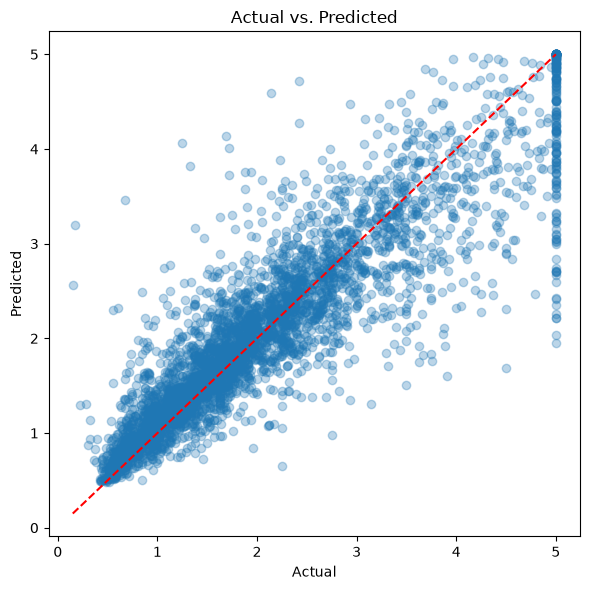

In [8]:
best_model = models['Random Forest']   # pick your best after seeing the table
y_pred = best_model.predict(X_test_scaled)

plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_pred, alpha=0.3)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')  # perfect-prediction line
plt.xlabel('Actual')
plt.ylabel('Predicted')
plt.title('Actual vs. Predicted')
plt.tight_layout()
plt.show()


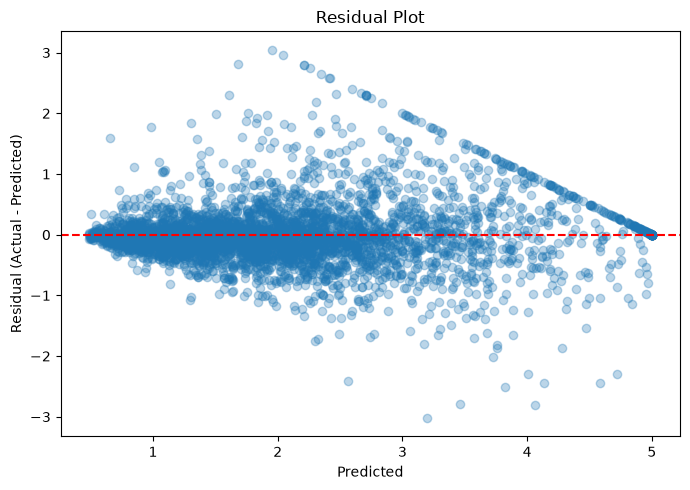

In [9]:
residuals = y_test - y_pred

plt.figure(figsize=(7, 5))
plt.scatter(y_pred, residuals, alpha=0.3)
plt.axhline(y=0, color='r', linestyle='--')
plt.xlabel('Predicted')
plt.ylabel('Residual (Actual - Predicted)')
plt.title('Residual Plot')
plt.tight_layout()
plt.show()


In [10]:
for name, model in models.items():
    train_r2 = model.score(X_train_scaled, y_train)
    test_r2 = model.score(X_test_scaled, y_test)
    print(f"{name}: Train R²={train_r2:.3f}, Test R²={test_r2:.3f}, Gap={train_r2 - test_r2:.3f}")


Linear Regression: Train R²=0.613, Test R²=0.576, Gap=0.037
Decision Tree: Train R²=1.000, Test R²=0.624, Gap=0.376
Random Forest: Train R²=0.974, Test R²=0.805, Gap=0.169


Random Forest performed best it had the lowest RMSE/MAE and the highest R² on the test set. It beats Linear Regression because house prices don't follow a straight-line relationship with the features, and it beats a single Decision Tree because averaging many trees reduces overfitting (the single tree showed a large train test gap).